# Speeding up A2C Training with Vector Envs

This tutorial demonstrates training with vector environments to it speed up.


## Notice

If you encounter an RuntimeError like the following comment raised on multiprocessing/spawn.py, wrap up the code from `gym.make_vec=` or `gym.vector.AsyncVectorEnv` to the end of the code by `if__name__ == '__main__'`.

`An attempt has been made to start a new process before the current process has finished its bootstrapping phase.`


---


## Introduction

In this tutorial, you'll learn how to use vectorized environments to train an Advantage Actor-Critic agent.
We are going to use A2C, which is the synchronous version of the A3C algorithm [1].

Vectorized environments [3] can help to achieve quicker and more robust training by allowing multiple instances
of the same environment to run in parallel (on multiple CPUs). This can significantly reduce the variance and thus speeds up the training.

We will implement an Advantage Actor-Critic from scratch to look at how you can feed batched states into your networks to get a vector of actions
(one action per environment) and calculate the losses for actor and critic on minibatches of transitions.
Each minibatch contains the transitions of one sampling phase: `n_steps_per_update` steps are executed in `n_envs` environments in parallel
(multiply the two to get the number of transitions in a minibatch). After each sampling phase, the losses are calculated and one gradient step is executed.
To calculate the advantages, we are going to use the Generalized Advantage Estimation (GAE) method [2], which balances the tradeoff
between variance and bias of the advantage estimates.

The A2C agent class is initialized with the number of features of the input state, the number of actions the agent can take,
the learning rates and the number of environments that run in parallel to collect experiences. The actor and critic networks are defined
and their respective optimizers are initialized. The forward pass of the networks takes in a batched vector of states and returns a tensor of state values
and a tensor of action logits. The select_action method returns a tuple of the chosen actions, the log-probs of those actions, and the state values for each action.
In addition, it also returns the entropy of the policy distribution, which is subtracted from the loss later (with a weighting factor `ent_coef`) to encourage exploration.

The get_losses function calculates the losses for the actor and critic networks (using GAE), which are then updated using the update_parameters function.


---


In [1]:
# Author: Till Zemann
# License: MIT License

from __future__ import annotations

import os

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.nn import functional as F
from torch import optim
from tqdm import tqdm

import gymnasium as gym
import pickle as pkl
print(torch.__version__)
from net.a2c import A2C, A2C_singleRNN

/cephfs/wangjiyi/miniconda3/envs/mixer/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


1.12.0


In [2]:
import os
os.getcwd()

'/cephfs/shared/jiyi/neurogym/docs/examples'

## Advantage Actor-Critic (A2C)

The Actor-Critic combines elements of value-based and policy-based methods. In A2C, the agent has two separate neural networks:
a critic network that estimates the state-value function, and an actor network that outputs logits for a categorical probability distribution over all actions.
The critic network is trained to minimize the mean squared error between the predicted state values and the actual returns received by the agent
(this is equivalent to minimizing the squared advantages, because the advantage of an action is as the difference between the return and the state-value: A(s,a) = Q(s,a) - V(s).
The actor network is trained to maximize the expected return by selecting actions that have high expected values according to the critic network.

The focus of this tutorial will not be on the details of A2C itself. Instead, the tutorial will focus on how to use vectorized environments
and domain randomization to accelerate the training process for A2C (and other reinforcement learning algorithms).


---


## Training the A2C Agent

For our training loop, we are using the `RecordEpisodeStatistics` wrapper to record the episode lengths and returns and we are also saving
the losses and entropies to plot them after the agent finished training.

You may notice that we don't reset the vectorized envs at the start of each episode like we would usually do.
This is because each environment resets automatically once the episode finishes (each environment takes a different number of timesteps to finish
an episode because of the random seeds). As a result, we are also not collecting data in `episodes`, but rather just play a certain number of steps
(`n_steps_per_update`) in each environment (as an example, this could mean that we play 20 timesteps to finish an episode and then
use the rest of the timesteps to begin a new one).


In [3]:
import copy
def train(configuration, n_updates, actor_lr, critic_lr, simple_type, ei_type, stop_eie_fraction):
    # environment hyperparams
    n_seed = 5
    n_envs = 10
    n_steps_per_update = 128
    randomize_domain = False

    # agent hyperparams
    gamma = 0.99
    lam = 0.95  # hyperparameter for GAE
    ent_coef = 0.01  # coefficient for the entropy bonus (to encourage exploration)

    hidden_size = 64

    env_name = "LunarLander-v3"
    # configuration = 'eisep_all'  # options: 'simple', 'eisep_actor', 'eisep_critic', 'eisep_all'
    # Note: the actor has a slower learning rate so that the value targets become
    # more stationary and are theirfore easier to estimate for the critic

    # environment setup
    if randomize_domain:
        envs = gym.vector.AsyncVectorEnv(
            [
                lambda: gym.make(
                    "LunarLander-v3",
                    gravity=np.clip(
                        np.random.normal(loc=-10.0, scale=1.0), a_min=-11.99, a_max=-0.01
                    ),
                    enable_wind=np.random.choice([True, False]),
                    wind_power=np.clip(
                        np.random.normal(loc=15.0, scale=1.0), a_min=0.01, a_max=19.99
                    ),
                    turbulence_power=np.clip(
                        np.random.normal(loc=1.5, scale=0.5), a_min=0.01, a_max=1.99
                    ),
                    max_episode_steps=500,
                )
                for i in range(n_envs)
            ]
        )

    else:
        envs = gym.make_vec(env_name, num_envs=n_envs, max_episode_steps=500)


    obs_shape = envs.single_observation_space.shape[0] # for LunarLander
    # obs_shape = envs.single_observation_space.n # for FrozenLake
    action_shape = envs.single_action_space.n # For LunarLander
    print(f"obs shape: {obs_shape}, action shape: {action_shape}")
    # action_shape = envs.single_action_space.shape[0]  # for HalfCheetah
    # print(f"obs shape: {obs_shape}, action shape: {action_shape}")
    # set the device
    use_cuda = False
    if use_cuda:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    else:
        device = torch.device("cpu")

    critic_losses = np.zeros((n_seed, n_updates))
    actor_losses = np.zeros((n_seed, n_updates))
    entropies = np.zeros((n_seed, n_updates))
    returns = np.zeros((n_seed, n_updates))
    net_state_dicts = [None] * n_seed
    critic_ei_entropy_loss = np.zeros((n_seed, n_updates))
    actor_ei_entropy_loss = np.zeros((n_seed, n_updates))

    for seed in range(n_seed):
        torch.manual_seed(seed+42)
        np.random.seed(seed+42)
        # init the agent
        if 'single' in configuration :
            print('Use single RNN A2C')
            agent = A2C_singleRNN(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size, configuration)
        else:
            agent = A2C(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size, configuration,
                    simple_type=simple_type, ei_type=ei_type)
        # create a wrapper environment to save episode returns and episode lengths
        envs = gym.make_vec(env_name, num_envs=n_envs, max_episode_steps=500)
        envs_wrapper = gym.wrappers.vector.RecordEpisodeStatistics(
            envs, buffer_length=n_envs * n_updates
        )
        print(f"stop_eie_fraction={stop_eie_fraction}, ei_entropy_loss_coef={agent.ei_entropy_loss_coef}")
        agent.train()
        prefix = configuration

        # Two-phase training:
        #   Phase 1 (steps 0 .. stop_eie_fraction * n_updates):
        #       Gumbel-Softmax soft E/I assignments + entropy regularisation (default coef=1.0).
        #   Phase 2 (steps after stop_eie_fraction * n_updates):
        #       Hard E/I sign assignments, entropy loss dropped (coef=0.0).
        # Setting stop_eie_fraction=1.0 keeps Gumbel-Softmax active for the full run.
        freeze_step = int(stop_eie_fraction * n_updates)
        ei_frozen = False

        for sample_phase in tqdm(range(n_updates)):
            # Freeze E/I signs once at the transition boundary.
            if not ei_frozen and sample_phase >= freeze_step:
                agent.ei_entropy_loss_coef = 0.0
                agent.set_temperature(-1, 'both')  # switch to hard (argmax) E/I assignments
                ei_frozen = True

            # we don't have to reset the envs, they just continue playing
            # until the episode is over and then reset automatically

            # reset lists that collect experiences of an episode (sample phase)
            ep_value_preds = torch.zeros(n_steps_per_update+1, n_envs, device=device)
            ep_rewards = torch.zeros(n_steps_per_update, n_envs, device=device)
            ep_action_log_probs = torch.zeros(n_steps_per_update, n_envs, device=device)
            ep_entropy = torch.zeros(n_steps_per_update, n_envs, device=device)
            masks = torch.zeros(n_steps_per_update, n_envs, device=device)

            # at the start of training reset all envs to get an initial state
            if sample_phase == 0:
                states, info = envs_wrapper.reset(seed=seed+42)
                hidden = agent.reset_hidden(batch_size=n_envs)

            hidden = agent.detach_hidden(hidden)
            for step in range(n_steps_per_update):
                # select an action A_{t} using S_{t} as input for the agent
                actions, action_log_probs, state_value_preds, entropy, new_hidden = agent.select_action(
                    states, hidden
                )
                # perform the action A_{t} in the environment to get S_{t+1} and R_{t+1}
                states, rewards, terminated, truncated, infos = envs_wrapper.step(
                    actions.cpu().numpy()
                )

                ep_value_preds[step] = torch.squeeze(state_value_preds)
                ep_rewards[step] = torch.tensor(rewards, device=device)
                ep_action_log_probs[step] = action_log_probs
                ep_entropy[step] = entropy

                # add a mask (for the return calculation later);
                # for each env the mask is 1 if the episode is ongoing and 0 if it is terminated (not by truncation!)
                done = np.logical_or(terminated, truncated)
                masks[step] = torch.tensor(~done, device=device, dtype=torch.float32)

                # reset hidden state for terminated environments
                hidden = agent.reset_hidden_on_done(new_hidden, done)

            with torch.no_grad():
                last_v, _, _ = agent.forward(states, hidden)
            ep_value_preds[-1] = last_v.squeeze(-1)  # shape: [n_envs]

            # calculate the losses for actor and critic
            critic_loss, actor_loss = agent.get_losses(
                ep_rewards,
                ep_action_log_probs,
                ep_value_preds,
                ep_entropy,
                masks,
                gamma,
                lam,
                ent_coef,
                device,
            )
            if hasattr(agent.critic, 'get_ei_entropy_loss'):
                critic_ei_entropy_loss[seed, sample_phase] = agent.critic.get_ei_entropy_loss()
            if hasattr(agent.actor, 'get_ei_entropy_loss'):
                actor_ei_entropy_loss[seed, sample_phase] = agent.actor.get_ei_entropy_loss()
            agent.update_parameters(critic_loss, actor_loss)

            critic_losses[seed, sample_phase] = critic_loss.detach().cpu().numpy()
            actor_losses[seed, sample_phase] = actor_loss.detach().cpu().numpy()
            entropies[seed, sample_phase] = ep_entropy.detach().mean().cpu().numpy()
            returns[seed, sample_phase] = np.mean(envs_wrapper.return_queue)
        net_state_dicts[seed] = copy.deepcopy(agent.state_dict())
    info = {
        'critic_loss': critic_losses,
        'actor_loss': actor_losses,
        'entropy': entropies,
        'net_state_dict': net_state_dicts,
        'rewards': returns,
        'critic_ei_entropy_loss': critic_ei_entropy_loss,
        'actor_ei_entropy_loss': actor_ei_entropy_loss
    }
    lrname=f'critic_{critic_lr}_actor_{actor_lr}'
    info_path = f'./rl/result/lunarlander/Trunc_{stop_eie_fraction}_simple_{simple_type}_ei_{ei_type}/{lrname}/{prefix}.pkl'
    os.makedirs(os.path.dirname(info_path), exist_ok=True)
    with open(info_path, 'wb') as f:
        pkl.dump(info, f)
    return info


In [ ]:
configurations = ['eisep_actor', 'eisep_critic', 'eisep_all']
actor_lrs = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]

simple_type = 'rnn'
ei_type = 'eisep'

# Reviewer experiment: compare two-phase training (freeze E/I at 25%) vs. full Gumbel-Softmax (1.0).
# stop_eie_fraction=0.25 uses Gumbel-Softmax + entropy loss for the first 25% of training, then
# switches to hard E/I assignments with no entropy overhead for the remaining 75%.
# stop_eie_fraction=1.0 keeps Gumbel-Softmax active throughout (full-run baseline).
for stop_eie_fraction in [0.9]:
    for actor_lr in actor_lrs:
        for critic_lr in critic_lrs:
            for config in configurations:
                print(f"Training: stop_eie_fraction={stop_eie_fraction}, config={config}, "
                      f"actor_lr={actor_lr}, critic_lr={critic_lr}")
                info = train(configuration=config, n_updates=1000, actor_lr=actor_lr, critic_lr=critic_lr,
                      simple_type=simple_type, ei_type=ei_type, stop_eie_fraction=stop_eie_fraction)


Training: stop_eie_fraction=0.25, config=eisep_actor, actor_lr=0.003, critic_lr=0.0015


/cephfs/wangjiyi/miniconda3/envs/mixer/lib/python3.9/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


obs shape: 8, action shape: 4
Using <class 'net.rnncell_variant.SimpleRNNCell'> for critic and <class 'net.rnncell_variant.EIRNNCell'> for actor
stop_eie_fraction=0.25, ei_entropy_loss_coef=1.0


100%|██████████| 1000/1000 [08:49<00:00,  1.89it/s]


Using <class 'net.rnncell_variant.SimpleRNNCell'> for critic and <class 'net.rnncell_variant.EIRNNCell'> for actor
stop_eie_fraction=0.25, ei_entropy_loss_coef=1.0


100%|██████████| 1000/1000 [09:09<00:00,  1.82it/s]


... (172 outputs left out)

Using <class 'net.rnncell_variant.EIRNNCell'> for actor and critic
stop_eie_fraction=0.9, ei_entropy_loss_coef=1.0


100%|██████████| 1000/1000 [11:06<00:00,  1.50it/s]


Using <class 'net.rnncell_variant.EIRNNCell'> for actor and critic
stop_eie_fraction=0.9, ei_entropy_loss_coef=1.0


100%|██████████| 1000/1000 [11:16<00:00,  1.48it/s]


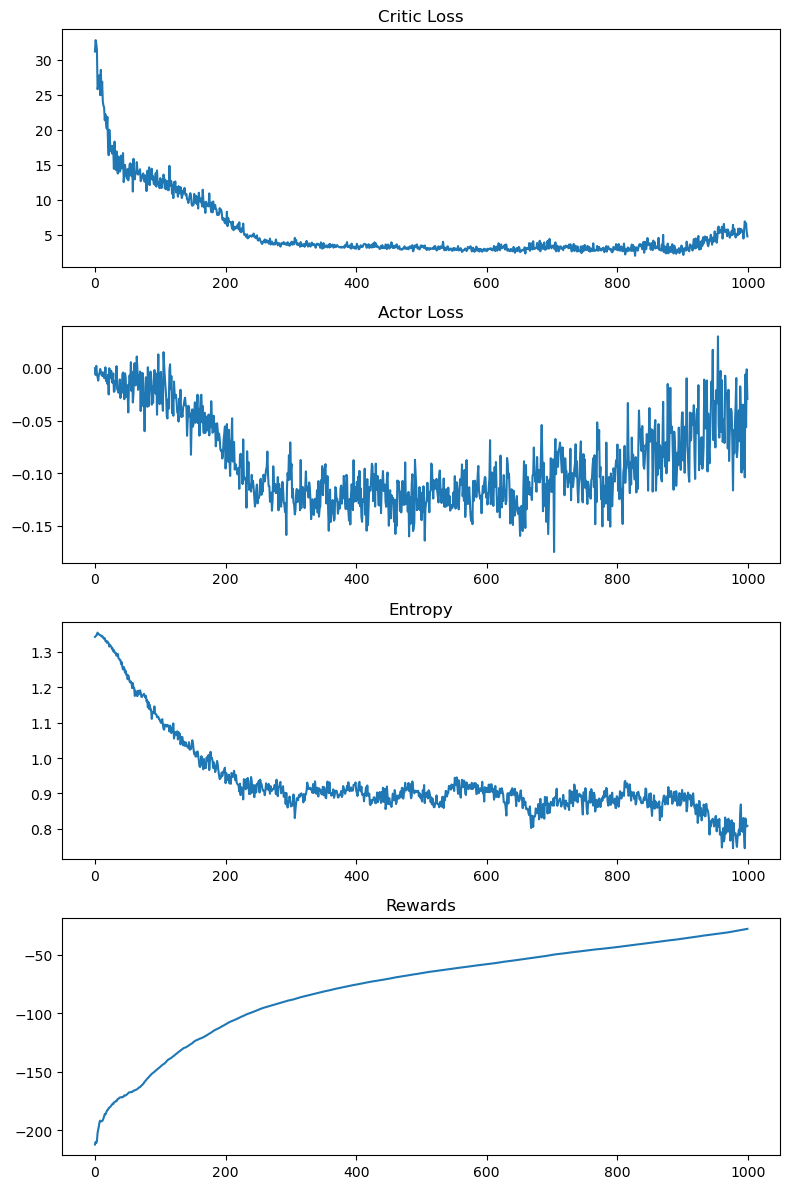

In [5]:
configuration = 'eisep_all'
info_path = f'./rl/result/lunarlander/simple_{simple_type}_ei_{ei_type}/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
with open(info_path, 'rb') as f:
    info = pkl.load(f)
critic_loss = info['critic_loss']
actor_loss = info['actor_loss']
entropies = info['entropy']
rewards = info['rewards']
fig, ax = plt.subplots(4, 1, figsize=(8, 12))
ax[0].plot(np.mean(critic_loss, axis=0))
ax[0].set_title('Critic Loss')
ax[1].plot(np.mean(actor_loss, axis=0))
ax[1].set_title('Actor Loss')
ax[2].plot(np.mean(entropies, axis=0))
ax[2].set_title('Entropy')
ax[3].plot(np.mean(rewards, axis=0))
ax[3].set_title('Rewards')
plt.tight_layout()
plt.show()


<img src="file://_static/img/tutorials/vector_env_a2c_training_plots.png" alt="training_plots">


## Performance Analysis of Synchronous and Asynchronous Vectorized Environments


---

Asynchronous environments can lead to quicker training times and a higher speedup
for data collection compared to synchronous environments. This is because asynchronous environments
allow multiple agents to interact with their environments in parallel,
while synchronous environments run multiple environments serially.
This results in better efficiency and faster training times for asynchronous environments.


<img src="file://_static/img/tutorials/vector_env_performance_plots.png" alt="performance_plots">


---

According to the Karp-Flatt metric (a metric used in parallel computing to estimate the limit for the
speedup when scaling up the number of parallel processes, here the number of environments),
the estimated max. speedup for asynchronous environments is 57, while the estimated maximum speedup
for synchronous environments is 21. This suggests that asynchronous environments have significantly
faster training times compared to synchronous environments (see graphs).


<img src="file://_static/img/tutorials/vector_env_karp_flatt_plot.png" alt="karp_flatt_metric">


---

However, it is important to note that increasing the number of parallel vector environments
can lead to slower training times after a certain number of environments (see plot below, where the
agent was trained until the mean training returns were above -120). The slower training times might occur
because the gradients of the environments are good enough after a relatively low number of environments
(especially if the environment is not very complex). In this case, increasing the number of environments
does not increase the learning speed, and actually increases the runtime, possibly due to the additional time
needed to calculate the gradients. For LunarLander-v3, the best performing configuration used a AsyncVectorEnv
with 10 parallel environments, but environments with a higher complexity may require more
parallel environments to achieve optimal performance.


<img src="file://_static/img/tutorials/vector_env_runtime_until_threshold.png" alt="runtime_until_threshold_plot">


FileNotFoundError: [Errno 2] No such file or directory: './rl/result/lunarlander/NoEnt_0.9_simple_rnn_ei_eisep/critic_0.0015_actor_0.0003/eisep_actor.pkl'

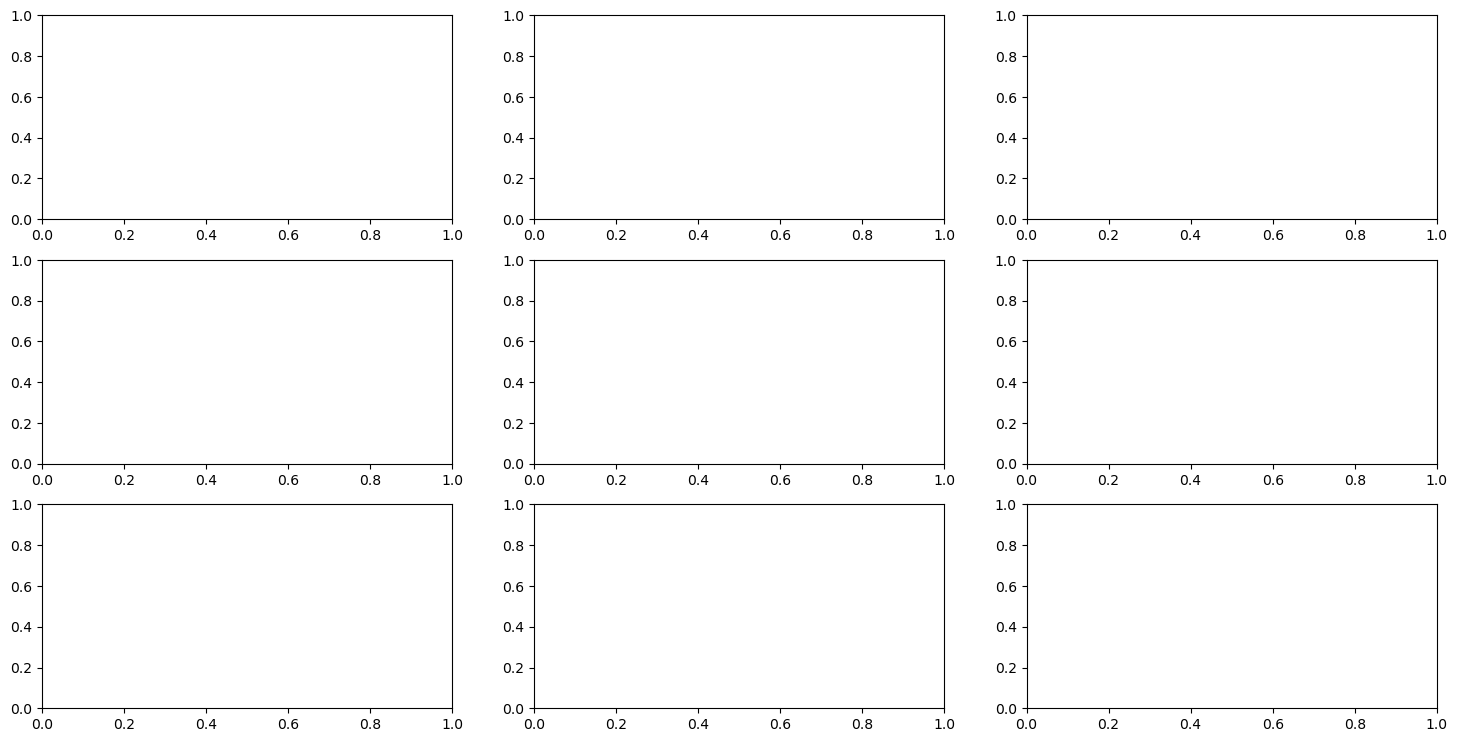

In [ ]:

actor_lrs = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['eisep_actor','eisep_critic','eisep_all']
n_showcase_episodes = 20
n_seed = 5
n_updates = 1000
critic_ei_entropy_losses = np.zeros((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, n_updates))
actor_ei_entropy_losses = np.zeros((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, n_updates))
simple_type = 'rnn'
ei_type = 'eisep'
fig, ax = plt.subplots(3,3,figsize=(18,9))
for a, actor_lr in enumerate(actor_lrs):
    for c, critic_lr in enumerate(critic_lrs):
        for i, configuration in enumerate(configurations):
            # env_name = "LunarLander-v3"
            # n_envs = 1
            # randomize_domain = False
            # hidden_size = 64
            # # environment setup
            # env = gym.make(env_name, max_episode_steps=500)
            # obs_shape = env.observation_space.shape[0]
            # action_shape = env.action_space.n
            # action_dim = 1
            if configuration == 'simple':
                info_path = f'./rl/result/lunarlander/simple_{simple_type}_ei_eisep/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
            else:
                info_path = f'./rl/result/lunarlander/Trunc_{stop_eie_fraction}_simple_{simple_type}_ei_{ei_type}/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
            with open(info_path, 'rb') as f:
                info = pkl.load(f)
            net_state_dicts = info['net_state_dict']
            critic_ei_entropy_loss = info['critic_ei_entropy_loss'] # (n_seed, n_sample_phase)
            actor_ei_entropy_loss = info['actor_ei_entropy_loss']  # (n_seed, n_sample_phase)
            # critic_ei_entropy_loss = info['critic_loss'] # (n_seed, n_sample_phase)
            # actor_ei_entropy_loss = info['actor_loss']  # (n_seed, n_sample_phase)
            mean_critic_eie = critic_ei_entropy_loss.mean(0)
            ste_critic_eie = critic_ei_entropy_loss.std(0)/np.sqrt(n_seed)
            mean_actor_eie = actor_ei_entropy_loss.mean(0)
            ste_actor_eie = actor_ei_entropy_loss.std(0)/np.sqrt(n_seed)
            ax[a,c].plot(np.arange(n_updates), mean_critic_eie, color='C0', label=f'critic, {critic_lr}')
            ax[a,c].fill_between(np.arange(n_updates), mean_critic_eie-ste_critic_eie,
                                mean_critic_eie+ste_critic_eie, color='C0')
            ax[a,c].plot(np.arange(n_updates), mean_actor_eie, color='C1', label=f'actor, {actor_lr}')
            ax[a,c].fill_between(np.arange(n_updates), mean_actor_eie-ste_actor_eie,
                                mean_actor_eie+ste_actor_eie, color='C1')
            ax[a,c].legend()
            ax[a,c].set_ylim(0,0.7)
            # ax[a,c].hlines(0.5, 0, n_updates, colors='k', linestyles='dashed')
plt.show()
            


In [ ]:
def entropy(p):
    return -p*np.log(p)-(1-p)*np.log(1-p)
print(entropy(0.1))

0.3250829733914482


## References

[1] V. Mnih, A. P. Badia, M. Mirza, A. Graves, T. P. Lillicrap, T. Harley, D. Silver, K. Kavukcuoglu. "Asynchronous Methods for Deep Reinforcement Learning" ICML (2016).

[2] J. Schulman, P. Moritz, S. Levine, M. Jordan and P. Abbeel. "High-dimensional continuous control using generalized advantage estimation." ICLR (2016).

[3] Gymnasium Documentation: Vector environments. (URL: https://gymnasium.farama.org/api/vector/)


In [ ]:
from net.dale_util import RL_Hidden_Buffer
def test(configuration, n_showcase_episodes, actor_lr, critic_lr, simple_type, ei_type, n_seed, stop_eie_fraction):
    env_name = "LunarLander-v3"

    # env_name = "MountainCar-v0"
    # configuration = 'eisep_all'  # options: 'simple', 'eisep_actor', 'eisep_critic', 'eisep_all'
    # Note: the actor has a slower learning rate so that the value targets become
    # more stationary and are theirfore easier to estimate for the critic
    # environment hyperparams
    n_envs = 1
    randomize_domain = False
    hidden_size = 64
    # environment setup
    if randomize_domain:
        env = gym.make(
            "LunarLander-v3",
            gravity=np.clip(
                np.random.normal(loc=-10.0, scale=2.0), a_min=-11.99, a_max=-0.01
            ),
            enable_wind=np.random.choice([True, False]),
            wind_power=np.clip(
                np.random.normal(loc=15.0, scale=2.0), a_min=0.01, a_max=19.99
            ),
            turbulence_power=np.clip(
                np.random.normal(loc=1.5, scale=1.0), a_min=0.01, a_max=1.99
            ),
            max_episode_steps=500,
        )
    else:
        env = gym.make(env_name, max_episode_steps=500)

    obs_shape = env.observation_space.shape[0]
    print('obs_shape', obs_shape)
    action_shape = env.action_space.n
    action_dim = 1

    # actor_weights_path = f"weights/{configuration}/actor_weights.h5"
    # critic_weights_path = f"weights/{configuration}/critic_weights.h5"
    if configuration == 'simple':
        info_path = f'./rl/result/lunarlander/simple_{simple_type}_ei_eisep/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
    else:
        info_path = f'./rl/result/lunarlander/Trunc_{stop_eie_fraction}_simple_{simple_type}_ei_{ei_type}/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
    # info_path = f'./rl/result/lunarlander/simple_{simple_type}_ei_{ei_type}/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
    print(f'Info from {info_path}')
    with open(info_path, 'rb') as f:
        info = pkl.load(f)
    net_state_dicts = info['net_state_dict']
    reward_ar = np.zeros((n_seed, n_showcase_episodes))
    for seed in range(n_seed):
        env = gym.make(env_name, max_episode_steps=500)
        buffer_path = info_path.replace('.pkl', f'_buffer{seed}.pkl')
        device = 'cuda'
        torch.manual_seed(seed)
        np.random.seed(seed)
        if 'single' in configuration:
            # agent = A2C_singleRNN(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size,
            #         configuration, simple_type=simple_type, ei_type=ei_type)
            agent = A2C_singleRNN(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size, configuration)
            n_h = 1
        else:
            agent = A2C(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size,
                    configuration, simple_type=simple_type, ei_type=ei_type)
            n_h = 2

        buffer = RL_Hidden_Buffer(100000, obs_shape, action_dim, hidden_size, n_h)
        agent.load_state_dict(net_state_dicts[seed])
        agent.eval()
        agent.to(device)

        for episode in range(n_showcase_episodes):
            # print(f"starting episode {episode}...")
            # get an initial state
            state, info = env.reset()
            # play one episode
            done = False
            hidden = agent.reset_hidden(batch_size=1)
            # hidden = torch.zeros((1, hidden_size), device=device)
            # hidden = (torch.zeros((1, hidden_size), device=device), torch.zeros((1, hidden_size), device=device))
            rewards = 0.
            while not done:
                # select an action A_{t} using S_{t} as input for the agent
                # tp = [None] * 5
                # tp[0] = state
                # tp[2] = hidden
                with torch.no_grad():
                    action, _, _, _, new_hidden = agent.select_action(state[None, :], hidden)
                # perform the action A_{t} in the environment to get S_{t+1} and R_{t+1}
                # print('action:', action)
                state, reward, terminated, truncated, info = env.step(action.item())
                # tp[1] = action
                # tp[3] = reward
                rewards += reward

                # update if the environment is done
                done = terminated or truncated

                # tp[4] = done
                # buffer.add(*tp)
                # h_critic, h_actor = new_hidden
                # h_critic = torch.where(torch.BoolTensor([[done]]).to(device), torch.zeros_like(h_critic).to(device), h_critic)
                # h_actor = torch.where(torch.BoolTensor([[done]]).to(device), torch.zeros_like(h_actor).to(device), h_actor)
                # hidden = (h_critic, h_actor)
                hidden = agent.reset_hidden_on_done(new_hidden, [done])
                # hidden = torch.where(torch.BoolTensor([[done]]).to(device), torch.zeros_like(hidden).to(device), new_hidden)

            reward_ar[seed, episode] = rewards
            print(f"Seed {seed}, episode {episode}, reward: {rewards}")

        buffer.episode_rewards = reward_ar[seed]
        # buffer.save(buffer_path)
        env.close()
    return reward_ar

In [ ]:
# from importlib import simple


actor_lrs = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['eisep_actor', 'eisep_critic', 'eisep_all']
# configurations = ['simple']
# actor_lrs = [0.001]
# critic_lrs = [0.005]
# configurations = ['entryei']
n_showcase_episodes = 20
n_seed = 5
reward_ars = np.zeros((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, n_showcase_episodes))
simple_type = 'rnn'
stop_eie_fraction = 0.25
# simple_type = 'linear'
# ei_type = 'eisep_init_DBPN'
ei_type = 'eisep'
for a, actor_lr in enumerate(actor_lrs):
    for c, critic_lr in enumerate(critic_lrs):
        for i, configuration in enumerate(configurations):
            print(f"Testing configuration: {configuration}, actor_lr: {actor_lr}, critic_lr: {critic_lr}, stop_eie_fraction: {stop_eie_fraction}")
            reward_ars[a,c,i] = test(configuration, n_showcase_episodes, actor_lr, critic_lr, simple_type, ei_type, n_seed, stop_eie_fraction)
            print(reward_ars[a,c,i])
# path = './result/lunarlander/dbpn/reward_ars.npy'
# os.makedirs(os.path.dirname(path), exist_ok=True)
raise ValueError('stop here')

Testing configuration: eisep_actor, actor_lr: 0.0003, critic_lr: 0.0015
obs_shape 8
Using <class 'net.rnncell_variant.SimpleRNNCell'> for critic and <class 'net.rnncell_variant.EIRNNCell'> for actor
Seed 0, episode 0, reward: -190.135998959652
Seed 0, episode 1, reward: 59.15140394973759
Seed 0, episode 2, reward: -104.51082428483993
Seed 0, episode 3, reward: 9.40268274943999
Seed 0, episode 4, reward: -66.50334794268903
Seed 0, episode 5, reward: 26.658449400051566
Seed 0, episode 6, reward: 20.60420473727335
Seed 0, episode 7, reward: -116.47725570874493
Seed 0, episode 8, reward: -3.2438048342344246
Seed 0, episode 9, reward: -21.063153665906327
Seed 0, episode 10, reward: -64.62492130426838
Seed 0, episode 11, reward: -33.106551677916286
Seed 0, episode 12, reward: -12.229046481954128
Seed 0, episode 13, reward: 6.0318809505653945
Seed 0, episode 14, reward: 12.849754878959331
Seed 0, episode 15, reward: -66.94466877469699
Seed 0, episode 16, reward: -2.742519770476018
Seed 0, epi

ValueError: stop here

In [ ]:
reward_ar_flatten = reward_ars.reshape(-1)
mean_r = np.mean(reward_ar_flatten, axis=-1)
ste_r = np.std(reward_ar_flatten, axis=-1)/np.sqrt(reward_ar_flatten.shape[-1])
print(mean_r, '+-', ste_r)

3.7410269346358556 +- 1.954030185708084


In [ ]:
filepath = f'./rl/result/lunarlander/NoEnt_1.0_simple_{simple_type}_ei_{ei_type}/reward_ars.npy'
np.save(filepath, reward_ars)
print(filepath)

./rl/result/lunarlander/NoEnt_1.0_simple_rnn_ei_eisep/reward_ars.npy


In [ ]:
fig, ax = plt.subplots(1,1,figsize=(3,3))
reward_ar_flatten = reward_ars.reshape(len(actor_lrs), len(critic_lrs), 1,  -1)

(3, 3, 4, 100)
[[[ 1.99003020e+01 -5.43017180e+01  6.99908087e+01 -7.50126242e+01]
  [ 1.06325459e+01 -5.42623702e+01  1.02573889e+02 -5.86453006e+01]
  [ 2.97877545e+00 -7.76396607e+01  7.08908205e+01 -2.55599394e+01]]

 [[ 1.45975302e+01  7.04072084e+00  6.67417869e+01  1.15652263e+01]
  [-6.08656788e+00  1.01330404e+01  1.01522050e+02  4.54143407e+01]
  [ 4.08106335e-02  9.75261667e+00  9.38141723e+01  3.78814731e+01]]

 [[ 1.19428648e+00 -5.25150393e+00  5.56539232e+00  3.19778169e+01]
  [-1.74425946e+01 -6.88961662e-01  6.13348229e+01  1.33909672e+02]
  [ 1.40921221e+01 -2.93292777e+01  1.41091799e+01  5.22313331e+01]]] +- [[[ 5.21371816  7.55770172  7.51046701 11.42183092]
  [ 3.27856887 10.73070929  5.78681923  8.9150123 ]
  [ 2.75074797 12.9593092   7.51745835  6.62698535]]

 [[ 2.96736863  3.08159287  7.519919    2.23584711]
  [ 2.6796183   3.94241861 10.21595302  7.84873097]
  [ 2.07185439  3.18652906  7.89404135  7.42920875]]

 [[ 5.6179149   2.52756076 11.13597763  3.614923

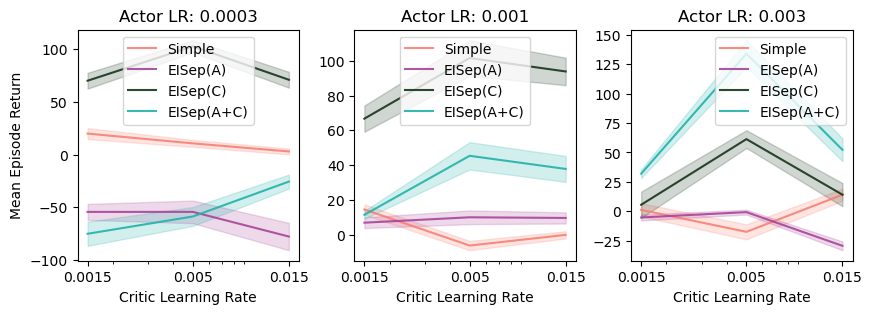

In [ ]:
configurations = ['eisep_actor','eisep_critic','eisep_all']
reward_ars = np.load(f'./rl/result/lunarlander/Trunc_0.25_simple_{simple_type}_ei_{ei_type}/reward_ars.npy')
reward_ar_flatten = reward_ars.reshape(len(actor_lrs), len(critic_lrs), len(configurations),  -1)
print(reward_ar_flatten.shape)
mean_r = np.mean(reward_ar_flatten, axis=-1)
ste_r = np.std(reward_ar_flatten, axis=-1)/np.sqrt(reward_ar_flatten.shape[-1])
print(mean_r, '+-', ste_r)
fig, ax = plt.subplots(1,3,figsize=(10,3))
# colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
colors = ['#A84499', '#183319', '#20B2AA']
config_names = ['EISep(A)', 'EISep(C)', 'EISep(A+C)']
# config_names = ['EISep(A+C)']
for i in range(len(actor_lrs)):
    for j in range(len(configurations)):
        ax[i].plot(critic_lrs, mean_r[i,:,j], label=config_names[j], alpha=0.9, color=colors[j])
        ax[i].fill_between(critic_lrs,
                          mean_r[i,:,j]-ste_r[i,:,j],
                          mean_r[i,:,j]+ste_r[i,:,j], alpha=0.2, color=colors[j])
    # ax[i].set_xticks(critic_lrs)
    ax[i].set_xlabel("Critic Learning Rate")

    ax[i].set_title(f"Actor LR: {actor_lrs[i]}")
    ax[i].legend()
    ax[i].set_xscale('log')
    ax[i].set_xticks(critic_lrs, labels=critic_lrs)
ax[0].set_ylabel("Mean Episode Return")
plt.subplots_adjust(wspace=0.25)
plt.show()
### normalized advantages: [[[32.59052909]]] +- [[[10.14511716]]]
### unnormalized advantages: [[[-7.594196]]] +- [[[8.45984122]]]

[[[-75.01262416 -52.65933519]
  [-58.64530056 -91.32270093]
  [-25.55993937 -53.0714312 ]]

 [[ 11.56522629  32.4200379 ]
  [ 45.41434073  61.43452507]
  [ 37.88147308  14.59693339]]

 [[ 31.97781694  39.42502335]
  [133.90967159  81.84641426]
  [ 52.23133313  86.21189473]]] +- [[[11.42183092  9.14821752]
  [ 8.9150123  11.86488912]
  [ 6.62698535  9.69576445]]

 [[ 2.23584711  4.49865325]
  [ 7.84873097  9.04863525]
  [ 7.42920875  7.81708746]]

 [[ 3.61492329  5.15333445]
  [11.4552411  11.93517513]
  [ 9.67995556  9.68696544]]]


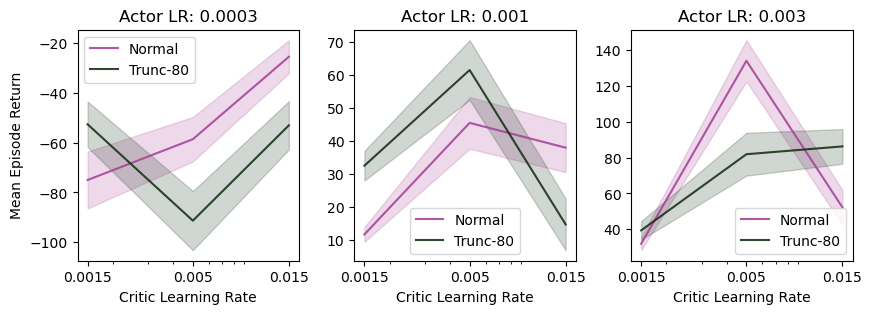

In [ ]:
dirnames = ['Trunc_0.25', 'Trunc_0.9', 'Trunc_1.0']
# dirnames = ['Truncate_0.8']
paths = [f'./rl/result/lunarlander/{prefix}_simple_{simple_type}_ei_{ei_type}/reward_ars.npy' for prefix in dirnames]
reward_ars_flatten = [np.load(path).reshape(len(actor_lrs), len(critic_lrs), 3,  -1) for path in paths]
normal_reward_ars = np.load(f'./rl/result/lunarlander/simple_{simple_type}_ei_{ei_type}/reward_ars.npy')
normal_reward_ar_flatten = normal_reward_ars.reshape(len(actor_lrs), len(critic_lrs), 4,  -1)[:,:,1:]
reward_ar_flatten = np.concatenate([normal_reward_ar_flatten]+reward_ars_flatten, axis=-2)
mean_r = np.mean(reward_ar_flatten, axis=-1)
ste_r = np.std(reward_ar_flatten, axis=-1)/np.sqrt(reward_ar_flatten.shape[-1])
print(mean_r, '+-', ste_r)
fig, ax = plt.subplots(1,3,figsize=(10,3))
# colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
colors = ['#A84499', '#183319', '#20B2AA', 'C2', 'C3']
# config_names = ['Simple', 'EISep(A)', 'EISep(C)', 'EISep(A+C)']
config_names = ['Normal', 'Trunc-25', 'Trunc-90', 'Trunc-100']
# config_names = ['Normal', 'Trunc-80']
for i in range(len(actor_lrs)):
    for j in range(len(config_names)):
        ax[i].plot(critic_lrs, mean_r[i,:,j], label=config_names[j], alpha=0.9, color=colors[j])
        ax[i].fill_between(critic_lrs,
                          mean_r[i,:,j]-ste_r[i,:,j],
                          mean_r[i,:,j]+ste_r[i,:,j], alpha=0.2, color=colors[j])
    # ax[i].set_xticks(critic_lrs)
    ax[i].set_xlabel("Critic Learning Rate")

    ax[i].set_title(f"Actor LR: {actor_lrs[i]}")
    ax[i].legend()
    ax[i].set_xscale('log')
    ax[i].set_xticks(critic_lrs, labels=critic_lrs)
ax[0].set_ylabel("Mean Episode Return")
plt.subplots_adjust(wspace=0.25)
plt.show()

./rl/output/lunarlander/truncated_proportions.png


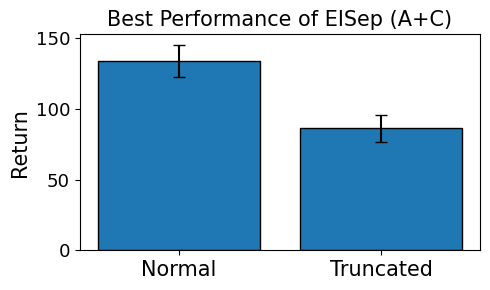

: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


dirnames = ['Trunc_0.25', 'Trunc_0.9']
# dirnames = ['Truncate_0.8']
n_showcase_episodes = 20
n_seed = 5
simple_type = 'rnn'
ei_type = 'eisep'
actor_lrs = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['eisep_actor', 'eisep_critic', 'eisep_all']
n_episode = n_showcase_episodes * n_seed
paths = [f'./rl/result/lunarlander/{prefix}_simple_{simple_type}_ei_{ei_type}/reward_ars.npy' for prefix in dirnames]
reward_ars_flatten = [np.load(path).reshape(len(actor_lrs), len(critic_lrs), 3,  n_episode) for path in paths]
normal_reward_ars = np.load(f'./rl/result/lunarlander/simple_{simple_type}_ei_{ei_type}/reward_ars.npy')
normal_reward_ar_flatten = normal_reward_ars.reshape(len(actor_lrs), len(critic_lrs), 4,  n_episode)[:,:,1:]
reward_ar_flatten_all = [normal_reward_ar_flatten] + reward_ars_flatten
config_names = ['Normal', 'Trunc-25', 'Trunc-90']

best_r_mean = np.zeros((len(config_names),))
best_r_ste = np.zeros((len(config_names), ))
for i in range(len(config_names)):
    reward_ar = reward_ar_flatten_all[i].reshape(len(actor_lrs)*len(critic_lrs), 3, n_episode)
    mean_r = np.mean(reward_ar, axis=-1)
    ste_r = np.std(reward_ar, axis=-1)/np.sqrt(reward_ar.shape[-1])
    best_r_idx = np.argmax(mean_r.reshape(-1))
    best_r_mean[i] = mean_r.reshape(-1)[best_r_idx]
    best_r_ste[i] = ste_r.reshape(-1)[best_r_idx]
    print('idx:', best_r_idx, 'best_r_mean: ', best_r_mean[i], 'best_r_ste: ', best_r_ste[i])
# mean_r = np.mean(reward_ar_flatten, axis=-1)
# ste_r = np.std(reward_ar_flatten, axis=-1)/np.sqrt(reward_ar_flatten.shape[-1])
# mean_r: shape = [len(actor_lrs), len(critic_lrs), n_models]
# ste_r : shape = [len(actor_lrs), len(critic_lrs), n_models]
# config_names = ['Normal', 'Trunc-25', 'Trunc-90', 'Trunc-100']
# config_names = ['Normal', 'Truncated']
# mean_r_all = mean_r.reshape(len(actor_lrs) * len(critic_lrs), len(config_names))
# ste_r_all  = ste_r.reshape(len(actor_lrs) * len(critic_lrs), len(config_names))

# 对每个模型，找出最佳 (actor_lr, critic_lr) 组合
# top_mean_r_idx = np.argmax(mean_r_all, axis=0)              # shape: [n_models]
# highest_r_all_model = mean_r_all[top_mean_r_idx, np.arange(len(config_names))]
# highest_ste_r_all_model = ste_r_all[top_mean_r_idx, np.arange(len(config_names))]

# 反推出最佳 lr 组合
# best_actor_idx, best_critic_idx = np.unravel_index(
#     top_mean_r_idx,
#     (len(actor_lrs), len(critic_lrs))
# )

# best_actor_lrs  = [actor_lrs[i] for i in best_actor_idx]
# best_critic_lrs = [critic_lrs[i] for i in best_critic_idx]

# ========= plot =========
fontsize = 15
x = np.arange(len(config_names))

fig, ax = plt.subplots(figsize=(6, 3))

bars = ax.bar(
    x,
    best_r_mean,
    yerr=best_r_ste,
    capsize=4,
    color=['C1','C0','C0'],
)
ax.set_ylim(0,170)
ax.bar_label(bars, fmt='%.2f', padding=2, fontsize=15)
ax.set_xticks(x)
ax.set_xticklabels(config_names, fontsize=fontsize)
ax.tick_params(axis='y', labelsize=fontsize-2)
ax.set_ylabel('Return', fontsize=fontsize)
ax.set_title('Reinforcement learning with truncation', fontsize=fontsize)


plt.tight_layout()
# plt.show()
from rl.rl_util import savefig
savefig('./rl/output/lunarlander/truncated_proportions.png', dpi=400)

In [ ]:


def plot_recurrent_weight(agent):
    # W_critic = agent.critic.get_actual_weight().detach().cpu().numpy()
    # W_actor = agent.actor.get_actual_weight().detach().cpu().numpy()
    W_critic = agent.critic_actor.get_actual_weight().detach().cpu().numpy()
    # sparsity_critic, exc_ratio_critic = score(W_critic, agent.critic)
    # sparsity_actor, exc_ratio_actor = score(W_actor, agent.actor)
    sparsity_critic, exc_ratio_critic = score(W_critic, agent.critic_actor)
    fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(4, 3))
    axs.set_title(f"Critic, sparsity={sparsity_critic:.2f}, exc_ratio={exc_ratio_critic:.2f}")
    limit = np.max(np.abs(W_critic))
    im0 = axs.imshow(W_critic, vmin=-limit, vmax=limit, cmap='bwr')
    plt.colorbar(im0, ax=axs)
    # axs[1].set_title(f"Actor, sparsity={sparsity_actor:.2f}, exc_ratio={exc_ratio_actor:.2f}")
    # limit = np.max(np.abs(W_actor))
    # im1 = axs[1].imshow(W_actor, vmin=-limit, vmax=limit, cmap='bwr')
    # plt.colorbar(im1, ax=axs[1])
    plt.suptitle("Recurrent weight matrices after training")
    plt.tight_layout()
    plt.show()
# plot_recurrent_weight(agent)

def plot_loss_curve(configurations):
    fig, ax = plt.subplots(1,4, figsize=(15,3))
    for configuration in configurations:
        info_path = f'./result/lunarlander/simple_rnn_ei_eisep/critic_None_actor_0.001/{configuration}.pkl'
        with open(info_path, 'rb') as f:
            info = pkl.load(f)
        critic_loss = info['critic_loss']
        actor_loss = info['actor_loss']
        entropy = info['entropy']
        reward = info['rewards']
        print('critic loss:', critic_loss.shape, 'actor_loss:', actor_loss.shape, 'entropy:', entropy.shape, 'reward:', len(reward))
        for r in reward:
            print('  reward length:', len(r), 'mean reward:', np.mean(r))
        ax[0].set_title("Critic Loss")
        mean_critic_loss = np.mean(critic_loss, axis=0)
        ste_critic_loss = np.std(critic_loss, axis=0)/np.sqrt(critic_loss.shape[0])
        ax[0].plot(mean_critic_loss, label=configuration, alpha=0.8)
        ax[0].fill_between(np.arange(len(mean_critic_loss)), mean_critic_loss - ste_critic_loss, mean_critic_loss + ste_critic_loss, alpha=0.2)
        ax[1].set_title("Actor Loss")
        mean_actor_loss = np.mean(actor_loss, axis=0)/np.sqrt(actor_loss.shape[0])
        ste_actor_loss = np.std(actor_loss, axis=0)/np.sqrt(actor_loss.shape[0])
        ax[1].plot(mean_actor_loss, label=configuration, alpha=0.8)
        ax[1].fill_between(np.arange(len(mean_actor_loss)), mean_actor_loss - ste_actor_loss, mean_actor_loss + ste_actor_loss, alpha=0.2)
        ax[2].set_title("Entropy")
        mean_entropy = np.mean(entropy, axis=0)
        ste_entropy = np.std(entropy, axis=0)/np.sqrt(entropy.shape[0])
        ax[2].plot(mean_entropy, label=configuration, alpha=0.8)
        ax[2].fill_between(np.arange(len(mean_entropy)), mean_entropy - ste_entropy, mean_entropy + ste_entropy, alpha=0.2)
        ax[3].set_title("Episode Return")
        reward_to_show = np.array([np.array(r)[-2500:] for r in reward])
        mean_reward = np.mean(reward_to_show, axis=0)
        reward_convolve = np.convolve(mean_reward, np.ones(20)/20, mode='same')
        mean_reward = reward_convolve
        ste_reward = np.std(reward_to_show, axis=0)/np.sqrt(reward_to_show.shape[0])
        ax[3].plot(mean_reward, label=configuration, alpha=0.8)
        ax[3].fill_between(np.arange(len(mean_reward)), mean_reward - ste_reward, mean_reward + ste_reward, alpha=0.2)
        for a in ax:
            a.set_xlabel("Training Updates")
            a.legend()
            # a.set_yscale('log')
    plt.tight_layout()
    plt.show()
    # for a in ax[:3]:
    #     a.set_xlabel("Training Updates")
    #     a.set_yscale('log')
# plot_loss_curve('simple')

FileNotFoundError: [Errno 2] No such file or directory: './result/lunarlander/simple_rnn_ei_eisep/critic_None_actor_0.001/simple.pkl'

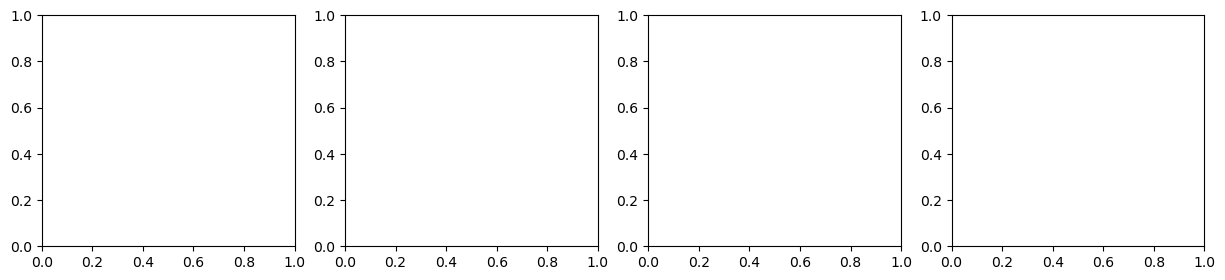

In [ ]:
plot_loss_curve(configurations)

In [ ]:
def score(weight, module):
    sparsity = 1 - np.mean(np.abs(weight)>0.1*np.std(np.abs(weight)))
    exc_ratio = -1
    if hasattr(module, 'get_ei_entropy_loss'):
        eimask_logit = module.eimask_logit.detach().cpu().numpy()
        exc_ratio = np.mean(eimask_logit[:,0]>eimask_logit[:,1])
    return sparsity, exc_ratio
def sparsity_analysis(configurations, critic_lr, actor_lr, simple_type, ei_type, task_name):
    # critic_lr = 0.005
    # actor_lr = 0.001
    hidden_size = 64
    env_name = "LunarLander-v3"
    colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
    config_names = ['Simple', 'EISep(A)', 'EISep(C)', 'EISep(A+C)']
    # configuration = 'eisep_all'  # options: 'simple', 'eisep_actor', 'eisep_critic', 'eisep_all'
    # Note: the actor has a slower learning rate so that the value targets become
    # more stationary and are theirfore easier to estimate for the critic
    # environment hyperparams
    n_seed = 5
    n_envs = 1
    randomize_domain = False
    hidden_size = 64
    if randomize_domain:
        env = gym.make(
            "LunarLander-v3",
            gravity=np.clip(
                np.random.normal(loc=-10.0, scale=2.0), a_min=-11.99, a_max=-0.01
            ),
            enable_wind=np.random.choice([True, False]),
            wind_power=np.clip(
                np.random.normal(loc=15.0, scale=2.0), a_min=0.01, a_max=19.99
            ),
            turbulence_power=np.clip(
                np.random.normal(loc=1.5, scale=1.0), a_min=0.01, a_max=1.99
            ),
            max_episode_steps=500,
        )
    else:
        env = gym.make(env_name, max_episode_steps=500)
    obs_shape = env.observation_space.shape[0]
    action_shape = env.action_space.n
    sparsity_all = np.zeros((len(configurations), n_seed, 2))
    for i, configuration in enumerate(configurations):
        info_path = f'./rl/result/{task_name}/simple_{simple_type}_ei_{ei_type}/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
        with open(info_path, 'rb') as f:
            info = pkl.load(f)
        net_state_dicts = info['net_state_dict']

        # environment setup

        device = 'cuda'
        # sparsity = np.zeros((n_seed, 2))
        for seed, state_dict in enumerate(net_state_dicts):
            # agent = A2C_singleRNN(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size, configuration)
            agent = A2C(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size, configuration,
                        simple_type, ei_type)
            agent.load_state_dict(net_state_dicts[seed])
            agent.eval()
            agent.to(device)
            # plot_recurrent_weight(agent)
            # W = agent.critic_actor.get_actual_weight().detach().cpu().numpy()
            W_critic = agent.critic.get_actual_weight().detach().cpu().numpy()
            W_actor = agent.actor.get_actual_weight().detach().cpu().numpy()
            sparsity_critic, exc_ratio_critic = score(W_critic, agent.critic)
            sparsity_actor, exc_ratio_actor = score(W_actor, agent.actor)
            sparsity_all[i, seed, 0] = sparsity_critic
            sparsity_all[i, seed, 1] = sparsity_actor
    return sparsity_all


In [ ]:
actor_lrs = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']
n_showcase_episodes = 20
n_seed = 5
sparsity_ars = np.zeros((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, 2))
simple_type = 'rnn'
ei_type = 'eisep'
task_name = 'lunarlander'
for a, actor_lr in enumerate(actor_lrs):
    for c, critic_lr in enumerate(critic_lrs):
        print(f"actor_lr: {actor_lr}, critic_lr: {critic_lr}")
        sparsity_ars[a,c] = sparsity_analysis(configurations, critic_lr, actor_lr, simple_type, ei_type, task_name)


actor_lr: 0.0003, critic_lr: 0.0015
Using <class 'net.rnncell_variant.SimpleLSTMCell'> RNN for actor and critic


RuntimeError: Error(s) in loading state_dict for A2C:
	size mismatch for critic.input_layer.weight: copying a param with shape torch.Size([256, 17]) from checkpoint, the shape in current model is torch.Size([256, 8]).
	size mismatch for actor.input_layer.weight: copying a param with shape torch.Size([256, 17]) from checkpoint, the shape in current model is torch.Size([256, 8]).
	size mismatch for actor.output_layer.weight: copying a param with shape torch.Size([12, 64]) from checkpoint, the shape in current model is torch.Size([4, 64]).
	size mismatch for actor.output_layer.bias: copying a param with shape torch.Size([12]) from checkpoint, the shape in current model is torch.Size([4]).

./rl/output/lunarlander/simple_rnn_ei_eisep/sparsity_averaged_across_lr.png


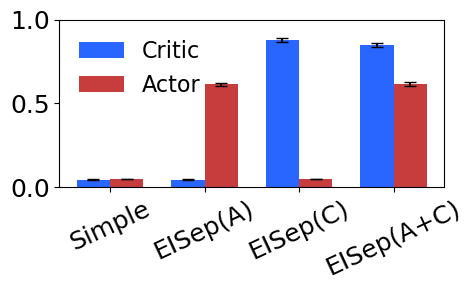

In [ ]:
from rl.rl_util import savefig
sparsity_flatten = sparsity_ars.transpose(2,0,1,3,4).reshape(len(configurations), -1, 2)

config_names = ['Simple', 'EISep(A)', 'EISep(C)', 'EISep(A+C)']
fig, ax = plt.subplots(figsize=(5,3))
fontsize = 20
x = np.arange(len(configurations))
width = 0.35
critic_means = np.mean(sparsity_flatten[:,:,0], axis=1)
critic_stes = np.std(sparsity_flatten[:,:,0], axis=1)/np.sqrt(sparsity_flatten.shape[1])
actor_means = np.mean(sparsity_flatten[:,:,1], axis=1)
actor_stes = np.std(sparsity_flatten[:,:,1], axis=1)/np.sqrt(sparsity_flatten.shape[1])
ax.bar(x - width/2, critic_means, width, yerr=critic_stes, label='Critic', capsize=4, color='#2965FF')
ax.bar(x + width/2, actor_means, width, yerr=actor_stes, label='Actor', capsize=4, color='#C73D3D')
ax.set_xticks(x)
ax.set_xticklabels(config_names, fontsize=fontsize, rotation=25)
ax.set_ylim(0,1)
# ax.set_title('Lun', fontsize=fontsize)
ax.tick_params(labelsize=fontsize-2)
ax.legend(fontsize=fontsize-4, frameon=False)
plt.tight_layout()
# plt.show()
savefig(f'./rl/output/lunarlander/simple_{simple_type}_ei_{ei_type}/sparsity_averaged_across_lr.png', dpi=400)

In [ ]:
# for a, actor_lr in enumerate(actor_lrs):
#     for c, critic_lr in enumerate(critic_lrs):
#         print(f"actor_lr: {actor_lr}, critic_lr: {critic_lr}")
#         sparsity_flatten = sparsity_ars[a,c]
#         fig, ax = plt.subplots(figsize=(5,3))
#         fontsize = 20
#         x = np.arange(len(configurations))
#         width = 0.35
#         critic_means = np.mean(sparsity_flatten[:,:,0], axis=1)
#         critic_stes = np.std(sparsity_flatten[:,:,0], axis=1)/np.sqrt(sparsity_flatten.shape[1])
#         actor_means = np.mean(sparsity_flatten[:,:,1], axis=1)
#         actor_stes = np.std(sparsity_flatten[:,:,1], axis=1)/np.sqrt(sparsity_flatten.shape[1])
#         ax.bar(x - width/2, critic_means, width, yerr=critic_stes, label='Critic', capsize=4, color='#2965FF')
#         ax.bar(x + width/2, actor_means, width, yerr=actor_stes, label='Actor', capsize=4, color='#C73D3D')
#         ax.set_xticks(x)
#         ax.set_xticklabels(config_names, fontsize=fontsize, rotation=15)
#         ax.set_title('Recurrent weight sparsity', fontsize=fontsize)
#         ax.tick_params(labelsize=fontsize-2)
#         ax.legend(fontsize=fontsize-4, frameon=False)
#         plt.tight_layout()
#         plt.show()
#         plt.close()

In [ ]:
from new_cut import signed_spectral_W, lift_spectral_W
config_names = ['Simple', 'EISep(A)', 'EISep(C)', 'EISep(A+C)']
actor_lrs = [0.0003, 0.001, 0.003]
critic_lrs = [0.0015, 0.005, 0.015]
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']
n_showcase_episodes = 20
n_seed = 5
sparsity_ars = np.zeros((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, 2))
simple_type = 'rnn'
ei_type = 'eisep'
task_name = 'lunarlander'
def modularity_analysis(configurations):
    critic_lr = 0.005
    actor_lr = 0.001
    hidden_size = 64
    env_name = "LunarLander-v3"
    # configuration = 'eisep_all'  # options: 'simple', 'eisep_actor', 'eisep_critic', 'eisep_all'
    # Note: the actor has a slower learning rate so that the value targets become
    # more stationary and are theirfore easier to estimate for the critic
    # environment hyperparams
    n_seed = 5
    n_envs = 1
    randomize_domain = False
    hidden_size = 64
    if randomize_domain:
        env = gym.make(
            "LunarLander-v3",
            gravity=np.clip(
                np.random.normal(loc=-10.0, scale=2.0), a_min=-11.99, a_max=-0.01
            ),
            enable_wind=np.random.choice([True, False]),
            wind_power=np.clip(
                np.random.normal(loc=15.0, scale=2.0), a_min=0.01, a_max=19.99
            ),
            turbulence_power=np.clip(
                np.random.normal(loc=1.5, scale=1.0), a_min=0.01, a_max=1.99
            ),
            max_episode_steps=500,
        )
    else:
        env = gym.make(env_name, max_episode_steps=500)
    obs_shape = env.observation_space.shape[0]
    action_shape = env.action_space.n
    print("Starting modularity analysis...", obs_shape, action_shape)
    # net_state_dicts: list of list of state_dict
    # model_names: list of model names
    # Returns: Q_all, Frustr_all, Ncut_all: [n_model, n_seed, n_k, 2]

    k_min = 2
    k_max = 10
    Q_all = np.zeros((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, k_max - k_min + 1, 2))
    Frustr_all = np.ones((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, k_max - k_min + 1, 2))
    Ncut_all = np.ones((len(actor_lrs), len(critic_lrs), len(configurations), n_seed, k_max - k_min + 1, 2))
    # Q_all = np.zeros((len(configurations), n_seed, k_max - k_min + 1, 2))
    # Frustr_all = np.ones((len(configurations), n_seed, k_max - k_min + 1, 2))
    # Ncut_all = np.ones((len(configurations), n_seed, k_max - k_min + 1, 2))
    for a, actor_lr in enumerate(actor_lrs):
        for c, critic_lr in enumerate(critic_lrs):
            for i, configuration in enumerate(configurations):
                info_path = f'./result/lunarlander/critic_{critic_lr}_actor_{actor_lr}/{configuration}.pkl'
                with open(info_path, 'rb') as f:
                    info = pkl.load(f)
                net_state_dicts = info['net_state_dict']

                # environment setup

                device = 'cuda'
                for seed, state_dict in enumerate(net_state_dicts):
                    agent = A2C(obs_shape, action_shape, device, critic_lr, actor_lr, n_envs, hidden_size, configuration)
                    agent.load_state_dict(net_state_dicts[seed])
                    agent.eval()
                    agent.to(device)
                    W_critic = agent.critic.get_actual_weight().detach().cpu().numpy()
                    W_actor = agent.actor.get_actual_weight().detach().cpu().numpy()

                    df_critic, _ = signed_spectral_W(W_critic.T, k_min, k_max, restarts=5, seed=0)
                    Q_all[a,c,i,seed,:,0] = df_critic['Q'].values
                    Frustr_all[a,c,i,seed,:,0] = df_critic['Frustr'].values
                    Ncut_all[a,c,i,seed,:,0] = df_critic['Ncut'].values

                    df_actor, _ = signed_spectral_W(W_actor.T, k_min, k_max, restarts=5, seed=0)
                    Q_all[a,c,i,seed,:,1] = df_actor['Q'].values
                    Frustr_all[a,c,i,seed,:,1] = df_actor['Frustr'].values
                    Ncut_all[a,c,i,seed,:,1] = df_actor['Ncut'].values


    return Q_all, Frustr_all, Ncut_all

In [ ]:
configurations = ['simple', 'eisep_actor', 'eisep_critic', 'eisep_all']
Q_all, Frustr_all, Ncut_all = modularity_analysis(configurations)
pkl.dump({'Q_all': Q_all, 'Frustr_all': Frustr_all, 'Ncut_all': Ncut_all}, open('./result/lunarlander/modularity_analysis.pkl', 'wb'))

Starting modularity analysis... 8 4


FileNotFoundError: [Errno 2] No such file or directory: './result/lunarlander/critic_0.0015_actor_0.0003/simple.pkl'

In [ ]:
from turtle import color


metric_name = ['Q', 'Frustration', 'Ncut']
colors = ['#FA7F72', '#A84499', '#183319', '#20B2AA']
k_min = 2
k_max = 10
fig, ax = plt.subplots(2,3, figsize=(12,6))
fontsize = 18
ax = ax.flatten()
Q_flatten = Q_all.transpose(2,0,1,3,4,5).reshape(len(configurations), -1, k_max - k_min + 1, 2)
Frustr_flatten = Frustr_all.transpose(2,0,1,3,4,5).reshape(len(configurations), -1, k_max - k_min + 1, 2)
Ncut_flatten = Ncut_all.transpose(2,0,1,3,4,5).reshape(len(configurations), -1, k_max - k_min + 1, 2)
for i, metric in enumerate([Q_flatten, Frustr_flatten, Ncut_flatten]):
    mean_metric = np.mean(metric, axis=1)
    ste_metric = np.std(metric, axis=1)/np.sqrt(metric.shape[1])
    for j in range(mean_metric.shape[0]):
        ax[i].plot(np.arange(k_min, k_max+1), mean_metric[j,:,0], label=f'{configurations[j]} Critic', alpha=0.9,
                   marker='o', markeredgecolor='white', markeredgewidth=1, markersize=10, color=colors[j])
        ax[i].fill_between(np.arange(k_min, k_max+1), mean_metric[j,:,0] - ste_metric[j,:,0], mean_metric[j,:,0] + ste_metric[j,:,0],
                           alpha=0.1, color=colors[j])
        ax[i+len(metric_name)].plot(np.arange(k_min, k_max+1), mean_metric[j,:,1], label=f'{configurations[j]} Actor', alpha=0.9,
                   marker='o', markeredgecolor='white', markeredgewidth=1, markersize=10, color=colors[j])
        ax[i+len(metric_name)].fill_between(np.arange(k_min, k_max+1), mean_metric[j,:,1] - ste_metric[j,:,1], mean_metric[j,:,1] + ste_metric[j,:,1],
                                            alpha=0.1, color=colors[j])
    # ax[i].legend()
    ax[i+len(metric_name)].set_xlabel("Number of clusters k", fontsize=fontsize)
    ax[i].tick_params(labelsize=fontsize)
    ax[i+len(metric_name)].tick_params(labelsize=fontsize)
    ax[i].set_xticks(np.arange(k_min, k_max+1))
    ax[i+len(metric_name)].set_xticks(np.arange(k_min, k_max+1))
ax[0].set_title("Modularity Q (Higher is better)", fontsize=fontsize)
ax[1].set_title("Frustration (Lower is better)", fontsize=fontsize)
ax[2].set_title("Normalized Cut (Lower is better)", fontsize=fontsize)
ax[0].set_ylabel("Critic", fontsize=fontsize)
ax[3].set_ylabel("Actor", fontsize=fontsize)
plt.tight_layout()
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(6,4))
config_names = ['Simple', 'EISep(A)', 'EISep(C)', 'EISep(A+C)']
for i in range(len(configurations)):
    ax.plot(0,0, label=f'{config_names[i]}', color=colors[i], alpha=1, linewidth=10)
ax.legend(fontsize=fontsize, loc='center', framealpha=1, shadow=True, markerscale=1)
ax.axis('off')
plt.show()